# 01 — EDA y política de columnas (DoS vs normal, MQTT_UAD)

Primer notebook de tres. Carga las capturas, describe el dataset, aplica la
política de columnas y deja un artefacto limpio para los otros dos:

| Notebook | Rol |
|---|---|
| `01_eda_politica.ipynb` | EDA, política de columnas y artefacto `df_raw` (este) |
| `02_tcp_vs_mqtt.ipynb` | Comparación A (features MQTT) vs B (features TCP) |
| `03_modelo_tcp.ipynb` | Modelo final B, ablaciones y export TCP |

Aquí **no se entrena ningún modelo** ni se construyen las matrices A/B.

Se usa `DoS.csv` completo y **solo el tráfico normal** de `MitM.csv` e
`Intrusion.csv`: sus frames MitM/Intrusion se descartan, no se reetiquetan.
Ningún ataque distinto de DoS entra al artefacto.

La captura admite todas las tramas; el agente clasifica frames IPv4/TCP con
endpoints completos y la carga aplica esa misma selección. Los CSV no tienen
`tcp.stream`: las sesiones se aproximan con endpoints y CONNECT (`_connection`,
`_direction`). IP, MAC, `client_id`, puertos crudos y reloj de captura solo
sirven de contexto o se excluyen.

**Salida:** `ML_Model/artifacts/df_raw.joblib` y `ML_Model/artifacts/manifest.json`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

SEED = 42
np.random.seed(SEED)


def find_repo_root(start=None):
    """Sube desde el cwd hasta la carpeta que contiene `dataset/` y `ML_Model/`."""
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'dataset').is_dir() and (candidate / 'ML_Model').is_dir():
            return candidate
    raise FileNotFoundError(f'No se encontró la raíz del repositorio desde {start}')


REPO_ROOT = find_repo_root()
MODEL_CODE_DIR = REPO_ROOT / 'ML_Model'
DATASET_DIR = REPO_ROOT / 'dataset'
ARTIFACTS_DIR = MODEL_CODE_DIR / 'artifacts'
if str(MODEL_CODE_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_CODE_DIR))
print('Repo:', REPO_ROOT)

Repo: /home/alejandropenagos/Escritorio/Alejandro/BigData/Proyecto


## 1. Load and select captured frames

`load_and_merge` reads the CSV, validates the fields needed for this pipeline,
normalizes each frame's `type` label, and keeps IPv4/TCP frames with complete
endpoints. It then builds `_connection` and `_direction` for later grouping.
This step reports how many frames are selected; it does not decide which
optional columns to drop based on missingness.


`NORMAL_ONLY` lists captures that contribute only their `normal` frames (MitM
and Intrusion); their attack frames are discarded before validation. The three
captures come from different dates and share no frames, and `_connection`
includes the capture name, so sessions never span files.

In [2]:
from data_preprocessing.load_data import TARGET_COL, load_and_merge

FILES = {name: DATASET_DIR / f'{name}.csv' for name in ['DoS', 'MitM', 'Intrusion']}

# MitM e Intrusion solo aportan tráfico normal: el modelo sigue siendo DoS vs normal.
NORMAL_ONLY = ['MitM', 'Intrusion']
df_raw = load_and_merge(FILES, normal_only=NORMAL_ONLY)
# Copia sin filtrar: la sección 2 la analiza y 2.7 crea el df_raw filtrado.
df_captured = df_raw
print(f'Selected IPv4/TCP dataset: {df_raw.shape}')
print(df_raw[TARGET_COL].value_counts())
print(pd.crosstab(df_raw['_capture'], df_raw[TARGET_COL], margins=True))

DoS: all frames: {'normal': 49111, 'DoS': 45514}
DoS: excluded due to invalid network context: 6165
DoS: selected IPv4/TCP frames: {'DoS': 45460, 'normal': 43000}
MitM: kept labels ['normal']; discarded {'mitm': 3855}
MitM: all frames: {'normal': 106813}
MitM: excluded due to invalid network context: 7679
MitM: selected IPv4/TCP frames: {'normal': 99134}
Intrusion: kept labels ['normal']; discarded {'intrusion': 1898}
Intrusion: all frames: {'normal': 78995}
Intrusion: excluded due to invalid network context: 9132
Intrusion: selected IPv4/TCP frames: {'normal': 69863}
Selected IPv4/TCP dataset: (257457, 72)
type
normal    211997
DoS        45460
Name: count, dtype: int64
type         DoS  normal     All
_capture                        
DoS        45460   43000   88460
Intrusion      0   69863   69863
MitM           0   99134   99134
All        45460  211997  257457


## 2. EDA y política de descarte de columnas (objetivo: detectar solo DoS)

El modelo distingue únicamente **DoS vs normal**, así que cada columna se juzga
solo frente a ese objetivo. Ninguna se descarta por su % de nulos: para cada una
se registra **semántica, motivo y acción**, y la evidencia sale de las tablas y
gráficas de esta sección.

Las mediciones están en `data_preprocessing/eda/` (no deciden nada) y las
decisiones en `data_preprocessing/column_policy.py` (`SEMANTICS` y
`build_column_policy`).

### Motivos

| motivo | qué significa | acción |
|---|---|---|
| `EMPTY` | 100% nula | DROP |
| `CONSTANT` | un solo valor observado | DROP |
| `DUPLICATE` | idéntica a otra columna en el 100% de filas | DROP; se indica cuál se conserva |
| `REDUNDANT` | se deriva sin pérdida de otra (verificado bit a bit) | DROP; se indica de cuál |
| `LEAKAGE` | identifica host, puerto efímero o momento de captura, no el comportamiento | DROP del valor crudo (DERIVE si se extrae una bandera) |
| `STRUCTURAL_NULL` | solo existe en cierto tipo de paquete | según la regla de abajo |
| `RAW_TEXT` | texto de aplicación (`mqtt.msg`, `mqtt.topic`) | DERIVE: longitud, entropía, nº de niveles |
| `BEHAVIOR` | siempre presente y describe el tráfico | KEEP |

`BEHAVIOR` es el motivo de las columnas que se conservan sin transformar
(`frame.len`, `frame.time_delta`), para que la tabla no tenga celdas vacías.

### Regla para `STRUCTURAL_NULL`

1. **Alineación**: los no nulos deben coincidir con un tipo de paquete concreto
   (índice de Jaccard ≥ 0.95 entre "tiene valor" y "es de ese tipo"). Si no
   coinciden, la columna mezcla significados y se hace DROP.
2. **Separación**: se compara la proporción de ese tipo en cada clase. Separa si
   una clase lo tiene al menos 2× más que la otra y hay ≥ 10 frames del tipo.
3. Si **no separa**: DROP con el motivo "no discrimina DoS".
4. Si **separa**: la columna cruda no se usa; se deriva un conteo o tasa del tipo
   por ventana o por `_connection` (p. ej. nº de CONNECT por ventana).
5. **Nunca** se imputa con 0 ni con la media: el nulo significa "no aplica".
   Las columnas MQTT que sí entran al modelo usan el centinela `-1`, fuera de su
   dominio (≥ 0).

Orden de evaluación por columna: `EMPTY` → motivos semánticos (`LEAKAGE`,
`RAW_TEXT`, `KEEP` declarados) → `REDUNDANT` verificado → `CONSTANT` →
`DUPLICATE` → `STRUCTURAL_NULL`. Una columna sin semántica escrita hace fallar
la política.

In [3]:
# Re-ejecutar en el mismo kernel recarga data_preprocessing y sus subcarpetas.
for name in [m for m in sys.modules if m.split('.')[0] == 'data_preprocessing']:
    del sys.modules[name]

from data_preprocessing.load_data import TARGET_COL
from data_preprocessing import eda
from data_preprocessing import column_policy as policy_module
from data_preprocessing.column_policy import build_column_policy, apply_column_policy
from data_preprocessing.artifacts import save_clean_artifact, class_counts

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 100)

### 2.1 Nulos por columna (solo descripción)

Se mide sobre los frames IPv4/TCP seleccionados. El % de nulos describe la
captura, pero **no decide**: una columna 99% nula puede ser la única que existe en
CONNECT. La gráfica coloreada por motivo aparece en 2.6, cuando ya hay política.

In [4]:
missingness = eda.missingness_report(df_captured)
print(f'Frames: {len(df_captured):,}; columnas capturadas: {len(missingness)}')
print('Columnas 100% nulas:', int(missingness['non_null_count'].eq(0).sum()))
print('Columnas parcialmente nulas:',
      int(missingness['non_null_count'].between(1, len(df_captured) - 1).sum()))
print('Columnas siempre presentes:', int(missingness['missing_count'].eq(0).sum()))
display(missingness)

Frames: 257,457; columnas capturadas: 66
Columnas 100% nulas: 19
Columnas parcialmente nulas: 30
Columnas siempre presentes: 17


,column,non_null_count,n_unique,missing_count,missing_pct
0,frame.coloring_rule.name,0,0,257457,100.00
1,frame.coloring_rule.string,0,0,257457,100.00
2,frame.comment,0,0,257457,100.00
3,frame.comment.expert,0,0,257457,100.00
4,frame.file_off,0,0,257457,100.00
5,frame.incomplete,0,0,257457,100.00
6,frame.interface_id,0,0,257457,100.00
7,frame.interface_name,0,0,257457,100.00
8,frame.link_nr,0,0,257457,100.00
9,frame.md5_hash,0,0,257457,100.00


### 2.2 Tipos de paquete MQTT por clase

El tipo se decodifica de los bits 7-4 de `mqtt.hdrflags`; `NO_MQTT` son frames
TCP sin capa MQTT (handshakes, ACK, otros servicios). Este reparto es la base de
la regla `STRUCTURAL_NULL`: una columna que solo existe en CONNECT solo puede
aportar lo que aporte la presencia de CONNECT. El eje es logarítmico porque hay
tipos con menos del 0.01% de frames.

type,DoS,normal,pct_DoS,pct_normal
packet_type,,,,
PUBLISH,37626,3933,82.767,1.855
NO_MQTT,6416,203972,14.114,96.215
CONNACK,361,108,0.794,0.051
PUBREL,339,0,0.746,0.000
CONNECT,313,153,0.689,0.072
DISCONNECT,175,1,0.385,0.000
PUBACK,162,0,0.356,0.000
PUBCOMP,35,0,0.077,0.000
RESERVED_0,22,0,0.048,0.000


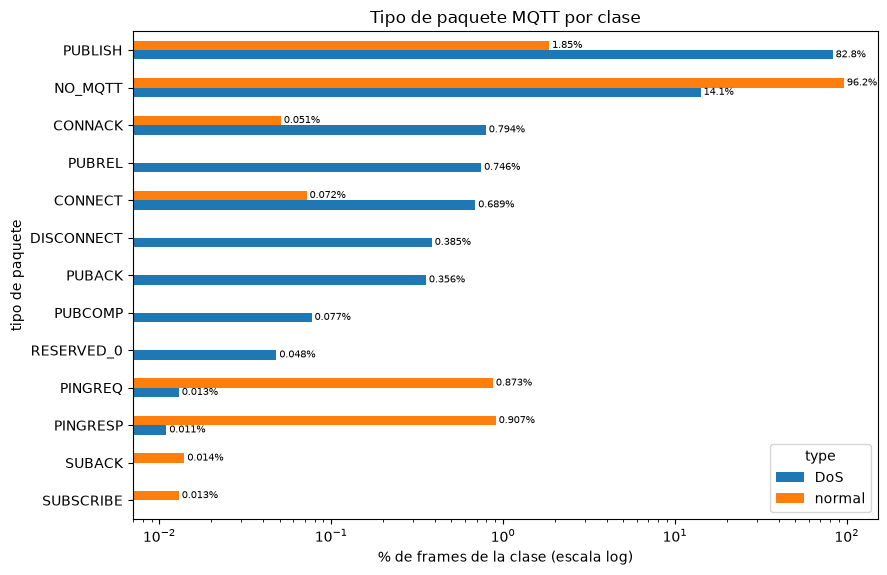

In [5]:
packet_table = eda.packet_type_by_class(df_captured)
display(packet_table)
eda.plot_packet_type_by_class(packet_table)

### 2.3 Rol del puerto MQTT por clase

`tcp.srcport`/`tcp.dstport` son `LEAKAGE` como valor crudo (puertos efímeros) y
solo se usan para derivar `fe_is_standard_mqtt_port` y `fe_is_broker_to_client`.
Esta tabla muestra cuánto separan esas banderas por sí solas.

**Hallazgo**: casi todo el tráfico `normal` de esta captura no usa el puerto
MQTT, mientras que casi todo el DoS va hacia el broker. Las banderas de puerto y
la presencia de MQTT son, en este dataset, casi un proxy de la etiqueta: el
modelo puede aprender "es MQTT" en lugar de "es DoS". Se tiene en cuenta al
interpretar las métricas; el análisis de distribuciones lo retoma.

type,DoS,normal,pct_DoS,pct_normal
port_role,,,,
broker -> cliente,4563,7023,10.04,3.31
cliente -> broker,40767,9301,89.68,4.39
sin puerto MQTT,130,195673,0.29,92.30


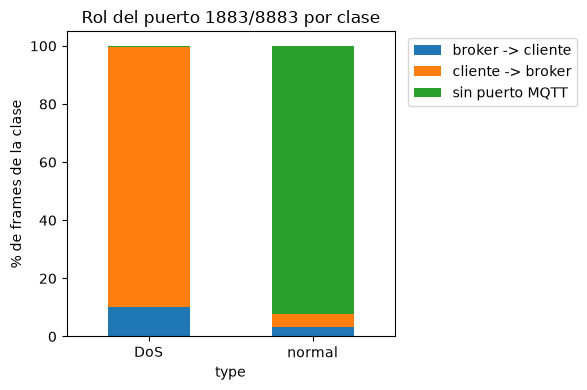

In [6]:
port_table = eda.port_role_by_class(df_captured)
display(port_table)
eda.plot_port_role_by_class(port_table)

#### 2.3.1 ¿MQTT = DoS? Verificación del proxy

La tabla anterior responde "dentro de cada clase, qué rol tiene el frame". Aquí
se invierte: **dentro de cada grupo de frames, qué % es DoS**. Los grupos
combinan el rol del puerto 1883/8883 con la presencia de capa MQTT
(`mqtt.hdrflags` no nulo).

Después se evalúan reglas triviales que no aprenden nada: "si usa el puerto MQTT
⇒ DoS" y "si tiene capa MQTT ⇒ DoS". Si una regla así ya consigue un macro-F1
alto, las métricas de los modelos deben compararse contra ella. Un modelo que no
la supere solo está aprendiendo "es MQTT".

type                             frames  % del total  % DoS  % normal
rol del puerto    capa                                               
broker -> cliente con capa MQTT    2707         1.05  11.64     88.36
                  sin capa MQTT    8879         3.45  47.84     52.16
cliente -> broker con capa MQTT   44362        17.23  87.30     12.70
                  sin capa MQTT    5706         2.22  35.72     64.28
sin puerto MQTT   sin capa MQTT  195803        76.05   0.07     99.93

,accuracy,balanced_accuracy,precision_DoS,recall_DoS,macro_f1
regla,,,,,
puerto MQTT => DoS,0.9361,0.9601,0.7352,0.9971,0.9030
cliente -> broker => DoS,0.9456,0.9264,0.8142,0.8968,0.9101
capa MQTT => DoS,0.9439,0.9105,0.8295,0.8589,0.9049
puerto MQTT y capa MQTT => DoS,0.9439,0.9105,0.8295,0.8589,0.9049


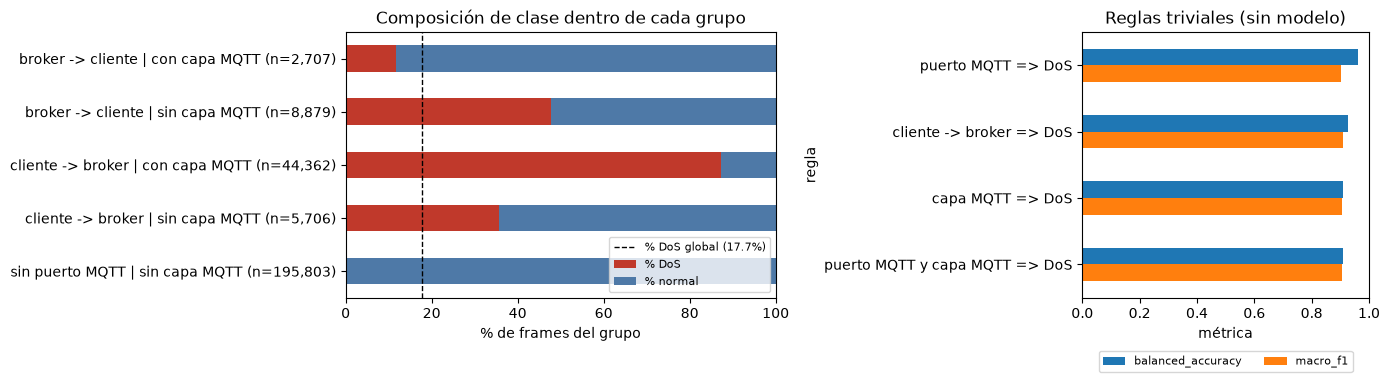

In [7]:
proxy_table = eda.mqtt_proxy_table(df_captured)
baseline = eda.trivial_rule_baseline(df_captured)
display(proxy_table)
display(baseline)
eda.plot_mqtt_proxy(proxy_table, baseline,
                    attack_share=df_captured[TARGET_COL].eq('DoS').mean())

#### 2.3.2 ¿Cambia la distribución al añadir el normal de MitM e Intrusion?

Se compara el tráfico normal de cada captura de origen y luego la misma regla
trivial de 2.3.1 ("puerto MQTT ⇒ DoS") con solo `DoS.csv` y con la mezcla. Si
el normal añadido usa más MQTT, la regla pierde precisión y el proxy
"MQTT = DoS" se debilita. Si no cambia, el normal extra no corrige el sesgo.

,frames normales,conexiones normales,% puerto MQTT,% capa MQTT,% PUBLISH,frame.len mediana
_capture,,,,,,
DoS,43000,697,2.25,1.14,0.55,612.0
Intrusion,69863,2067,11.02,5.67,2.44,74.0
MitM,99134,864,7.72,3.60,2.01,353.0


_capture,DoS,Intrusion,MitM
packet_type,,,
NO_MQTT,98.858,94.329,96.397
PUBLISH,0.551,2.445,2.005
PINGRESP,0.256,1.439,0.814
PINGREQ,0.253,1.397,0.773
CONNACK,0.040,0.120,0.007
CONNECT,0.023,0.199,0.004
SUBACK,0.009,0.036,0.000
SUBSCRIBE,0.009,0.034,0.000
DISCONNECT,0.000,0.001,0.000


,frames,% DoS,balanced_accuracy,precision_DoS,recall_DoS,macro_f1
datos,,,,,,
solo DoS.csv,88460,51.39,0.9873,0.9791,0.9971,0.9876
DoS.csv + normal de las demás,257457,17.66,0.9601,0.7352,0.9971,0.9030


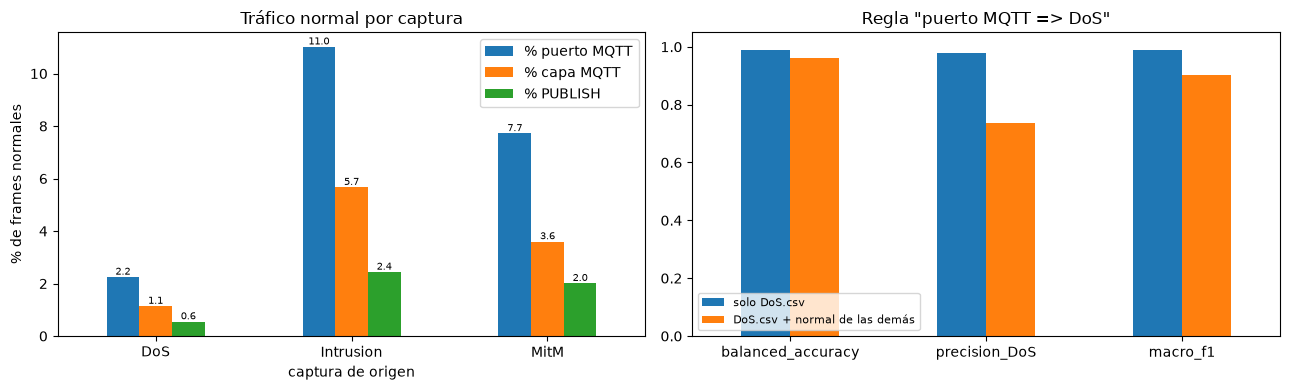

In [8]:
normal_profile = eda.normal_profile_by_capture(df_captured)
rule_comparison = eda.port_rule_by_scope(df_captured, attack_capture='DoS')
display(normal_profile)
display(eda.normal_packet_types_by_capture(df_captured))
display(rule_comparison)
eda.plot_normal_by_capture(normal_profile, rule_comparison)

#### 2.3.3 ¿El tráfico normal de DoS, MitM e Intrusion es el mismo?

Si las tres capturas tienen el mismo tipo de tráfico normal, mezclarlas solo
añade volumen. Si son distintas, el modelo puede aprender "de qué captura viene"
en lugar de "es DoS". La evaluación tiene cuatro partes, todas solo con frames normales:

1. **Numéricas**: mediana/IQR y estadístico KS `D` por pares. Con cientos de
   miles de frames cualquier p-valor es ~0, así que se usa `D` como tamaño de
   efecto: < 0.1 pequeño, 0.1–0.3 moderado, > 0.3 grande. `frame.time_delta` se
   mide entre frames consecutivos de toda la captura, así que también refleja
   cuánto tráfico total había ese día.
2. **Categóricas**: tipo de paquete y rol del puerto, con distancia de
   Jensen-Shannon por pares (0 = idénticas, 1 = disjuntas).
3. **Hosts**: solapamiento (Jaccard) de las IP vistas en cada captura.
4. **Clasificador de origen**: un modelo intenta adivinar la captura de cada
   frame normal con 5-fold agrupado por conexión. El azar es 1/3 de balanced
   accuracy. Cuanto más se acerque a 1, más distintas son las capturas.

**1. Numéricas** — mediana/IQR por captura y KS D por pares (< 0.1 pequeño, 0.1–0.3 moderado, > 0.3 grande).

In [9]:
display(eda.numeric_summary_by_capture(df_captured))
display(eda.ks_by_capture_pair(df_captured))

,frame.len mediana,frame.len IQR,frame.time_delta mediana,frame.time_delta IQR,mqtt.len mediana,mqtt.len IQR,mqtt.topic_len mediana,mqtt.topic_len IQR,% con capa MQTT
_capture,,,,,,,,,
DoS,612.0,1448.0,0.00013,0.00096,8.0,14.0,11.0,9.0,1.14186
Intrusion,74.0,954.5,0.00050,0.00423,0.0,25.0,20.0,0.0,5.67110
MitM,353.0,1448.0,0.00013,0.00122,25.0,25.0,20.0,0.0,3.60320


,DoS vs Intrusion,DoS vs MitM,Intrusion vs MitM
frame.len,0.303,0.100,0.288
frame.time_delta,0.181,0.074,0.141
mqtt.len,0.343,0.470,0.128
mqtt.topic_len,0.608,0.639,0.030


**2. Categóricas** — distancia de Jensen-Shannon por pares (0 = idénticas, 1 = disjuntas) y puertos de servicio más frecuentes.

In [10]:
display(eda.js_by_capture_pair(df_captured))
display(eda.top_service_ports(df_captured, top=8))

,DoS vs Intrusion,DoS vs MitM,Intrusion vs MitM
tipo de paquete,0.111,0.075,0.057
rol del puerto,0.156,0.110,0.049
puerto de servicio,0.348,0.352,0.059


_capture,DoS,Intrusion,MitM
puerto,,,
443,52.63,72.77,78.08
80,30.02,3.60,3.04
efímero/otro,15.07,12.61,11.11
1883,2.25,11.02,7.72
22,0.03,0.00,0.04


**3. Hosts** — solapamiento de IP entre capturas.

In [11]:
display(eda.host_overlap(df_captured))

,IPs en A,IPs en B,IPs compartidas,Jaccard
par,,,,
DoS vs Intrusion,176,427,63,0.117
DoS vs MitM,176,234,45,0.123
Intrusion vs MitM,427,234,40,0.064


**4. Clasificador de origen** — 5-fold agrupado por conexión; azar = 1/3 de balanced accuracy.

Clasificador de origen: balanced accuracy = 0.485 (azar = 0.333)


,pred DoS,pred Intrusion,pred MitM
real DoS,0.527,0.261,0.212
real Intrusion,0.254,0.639,0.106
real MitM,0.429,0.284,0.287


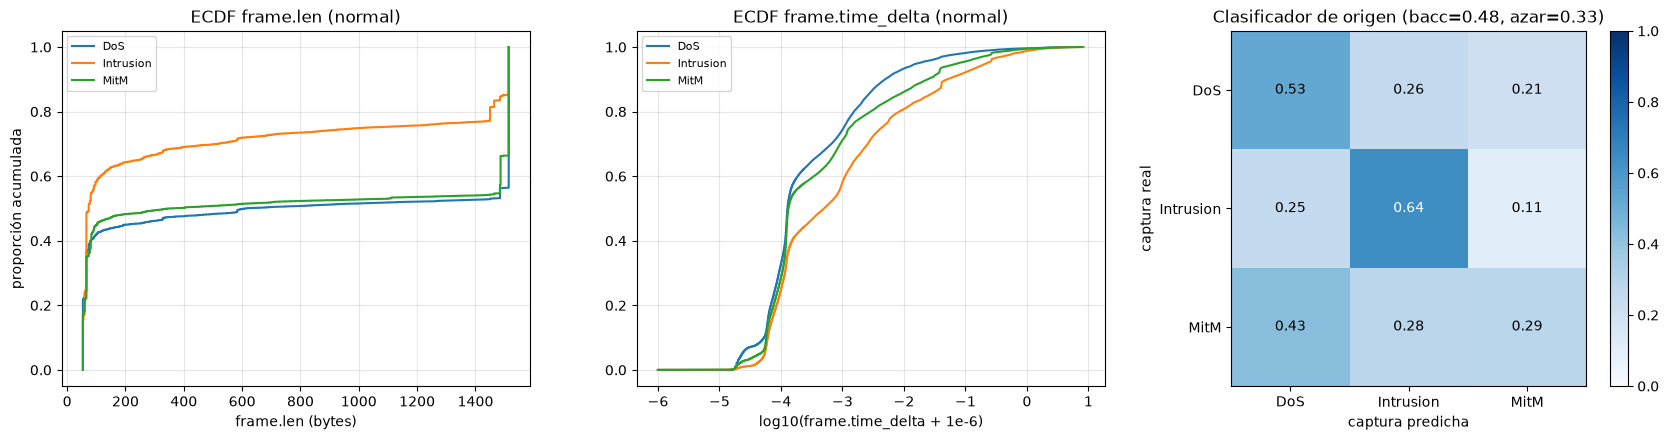

In [12]:
origin_bacc, origin_cm = eda.origin_classifier(df_captured, seed=SEED)
print(f'Clasificador de origen: balanced accuracy = {origin_bacc:.3f} (azar = 0.333)')
display(origin_cm)
eda.plot_capture_similarity(df_captured, origin_bacc, origin_cm)

#### 2.3.4 Concurrencia temporal del normal en `DoS.csv`

Antes de decidir el split hay que saber si el normal de `DoS.csv` existe durante
el ataque o solo antes/después. Se miran dos vistas con `frame.time_epoch`: puntos
por frame y frames por segundo apilados por clase. Se repiten solo con frames del
puerto 1883/8883, que es el alcance de la comparación A/B de `02_tcp_vs_mqtt.ipynb`.

La tabla final compara los frames normales antes, durante y después de la ventana
`[primer DoS, último DoS]`, en total y solo MQTT.

**Decisión.** Si ≥ 20 % del normal MQTT de `DoS.csv` cae dentro de la ventana, se
mantiene la división agrupada por conexión. Si no, además se evaluará
*leave-one-capture-out* del normal para separar "reconoce normal" de "reconoce
antes/después del ataque".

,normal_total,normal_mqtt,DoS_total,DoS_mqtt
ventana,,,,
antes,12263,198,0,0
durante,23306,568,45460,45330
después,7431,203,0,0
total,43000,969,45460,45330


Ventana DoS: 1522235596.011 -> 1522236159.872 (563.9 s)
Normal MQTT de DoS.csv dentro de la ventana: 568/969 = 58.6%
Split: agrupado por conexión


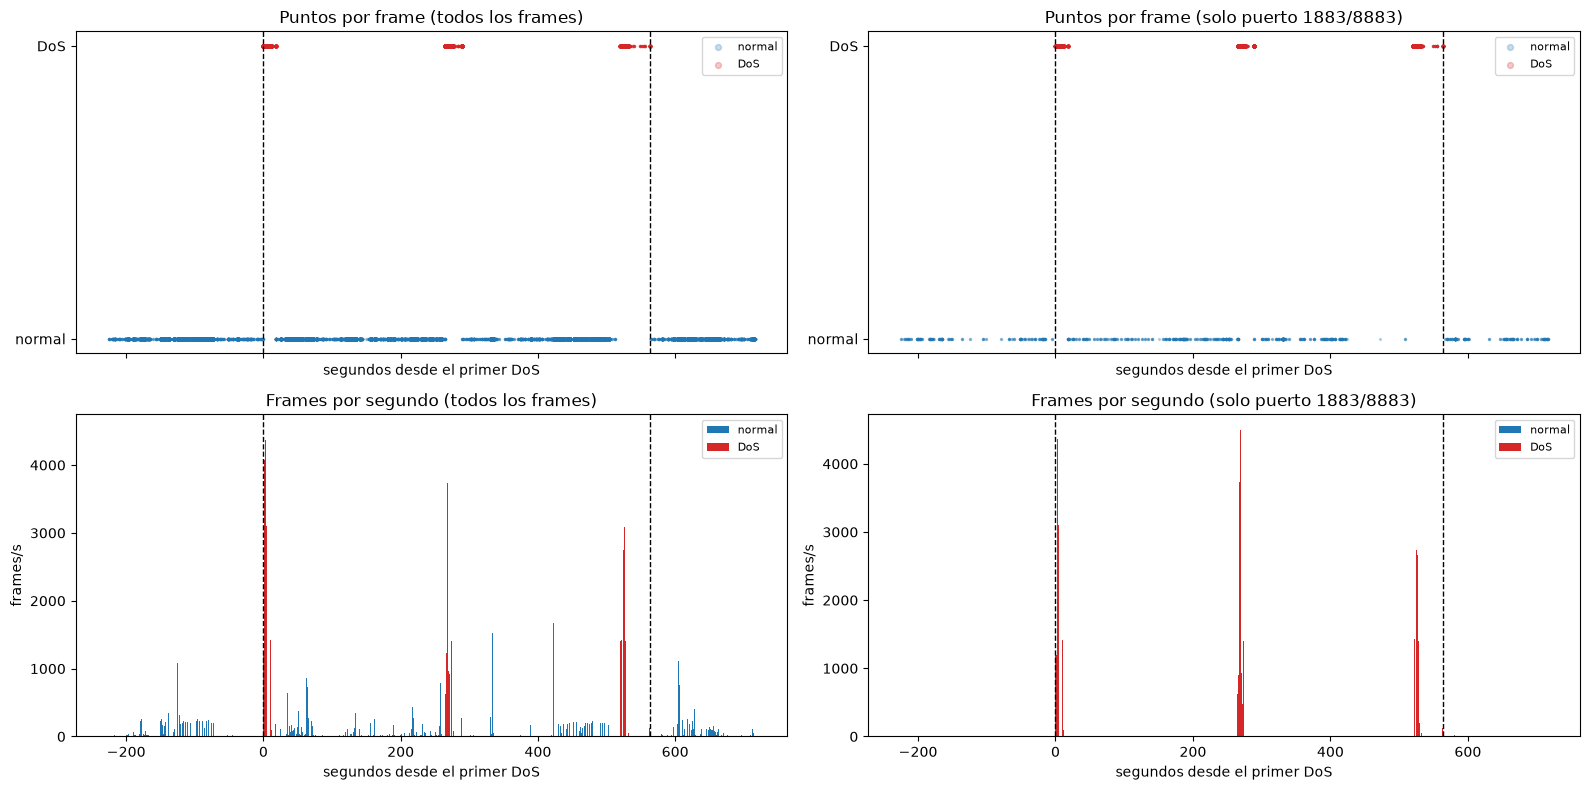

In [13]:
attack_start, attack_end = eda.attack_window(df_captured, capture='DoS')
display(eda.temporal_table(df_captured, capture='DoS'))

normal_mqtt_during, normal_mqtt_total, NORMAL_CONCURRENT_SHARE = \
    eda.concurrent_normal_share(df_captured, capture='DoS')
NEEDS_LOCO = NORMAL_CONCURRENT_SHARE < 0.20  # Decisión: umbral del 20 %.
print(f'Ventana DoS: {attack_start:.3f} -> {attack_end:.3f} ({attack_end - attack_start:.1f} s)')
print(f'Normal MQTT de DoS.csv dentro de la ventana: '
      f'{normal_mqtt_during}/{normal_mqtt_total} = {NORMAL_CONCURRENT_SHARE:.1%}')
print('Split:', 'agrupado por conexión' if not NEEDS_LOCO
      else 'agrupado + leave-one-capture-out del normal')
eda.plot_temporal_concurrency(df_captured, capture='DoS')

### 2.4 Duplicadas y redundantes

- **DUPLICATE**: columnas idénticas celda a celda (nulos incluidos). Se conserva
  la que usa el modelo o, si ninguna, la primera.
- **REDUNDANT**: `mqtt.msgtype`, `mqtt.dupflag`, `mqtt.qos` y `mqtt.retain` son
  bits de `mqtt.hdrflags`. Se verifican donde tienen significado: el tipo en todo
  frame MQTT y DUP/QoS/RETAIN solo en PUBLISH (MQTT 3.1.1). Fuera de PUBLISH
  tshark también rellena esos campos aunque los bits no signifiquen eso; esas
  diferencias se cuentan aparte y no invalidan la redundancia.

In [14]:
display(eda.duplicate_columns(df_captured, preferred=policy_module.PREFERRED_COLUMNS))
display(eda.hdrflags_redundancy(df_captured))

,duplicate_of
column,
frame.time_delta_displayed,frame.time_delta
frame.cap_len,frame.len
frame.marked,frame.ignored
mqtt.conflag.qos,mqtt.conflag.passwd
mqtt.conflag.reserved,mqtt.conflag.passwd
mqtt.conflag.retain,mqtt.conflag.passwd
mqtt.conflag.uname,mqtt.conflag.passwd
mqtt.conflag.willflag,mqtt.conflag.passwd


,source,bits,scope,compared_in_scope,mismatches_in_scope,mismatches_out_of_scope,out_of_scope_types,only_in_derived
column,,,,,,,,
mqtt.msgtype,mqtt.hdrflags,7-4,MQTT,47069,0,0,-,0
mqtt.dupflag,mqtt.hdrflags,3-3,PUBLISH,41559,0,230,"PUBREL=86, PUBACK=66, CONNACK=54, RESERVED_0=20, PUBCOMP=4",0
mqtt.qos,mqtt.hdrflags,2-1,PUBLISH,41559,0,442,"PUBREL=294, PUBACK=100, RESERVED_0=20, PUBCOMP=16, CONNACK=12",0
mqtt.retain,mqtt.hdrflags,0-0,PUBLISH,41559,0,289,"PUBREL=162, PUBACK=71, CONNACK=54, RESERVED_0=2",0


### 2.5 `STRUCTURAL_NULL`: alineación y separación

**Paso 1.** El heatmap muestra, para cada columna parcialmente nula, en qué % de
los frames de cada tipo tiene valor. Una columna alineada tiene una sola celda
llena, como las de CONNECT. `mqtt.conack.*` y `mqtt.msgid` aparecen en varios
tipos: no son "campos de CONNACK" en esta captura y se descartan.

**Paso 2.** La tabla y el scatter comparan la proporción de cada tipo en normal y
DoS; la diagonal es "misma proporción". Los puntos rojos separan.

,non_null,best_group,jaccard,precision,coverage,aligned,non_null_by_type
column,,,,,,,
mqtt.sub.qos,28,SUBSCRIBE,1.0000,1.000000,1.000000,True,SUBSCRIBE=28
mqtt.suback.qos,29,SUBACK,1.0000,1.000000,1.000000,True,SUBACK=29
mqtt.clientid,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466
mqtt.clientid_len,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466
mqtt.conflag.cleansess,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466
mqtt.conflag.passwd,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466
mqtt.conflag.qos,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466
mqtt.conflag.reserved,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466
mqtt.conflag.retain,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466


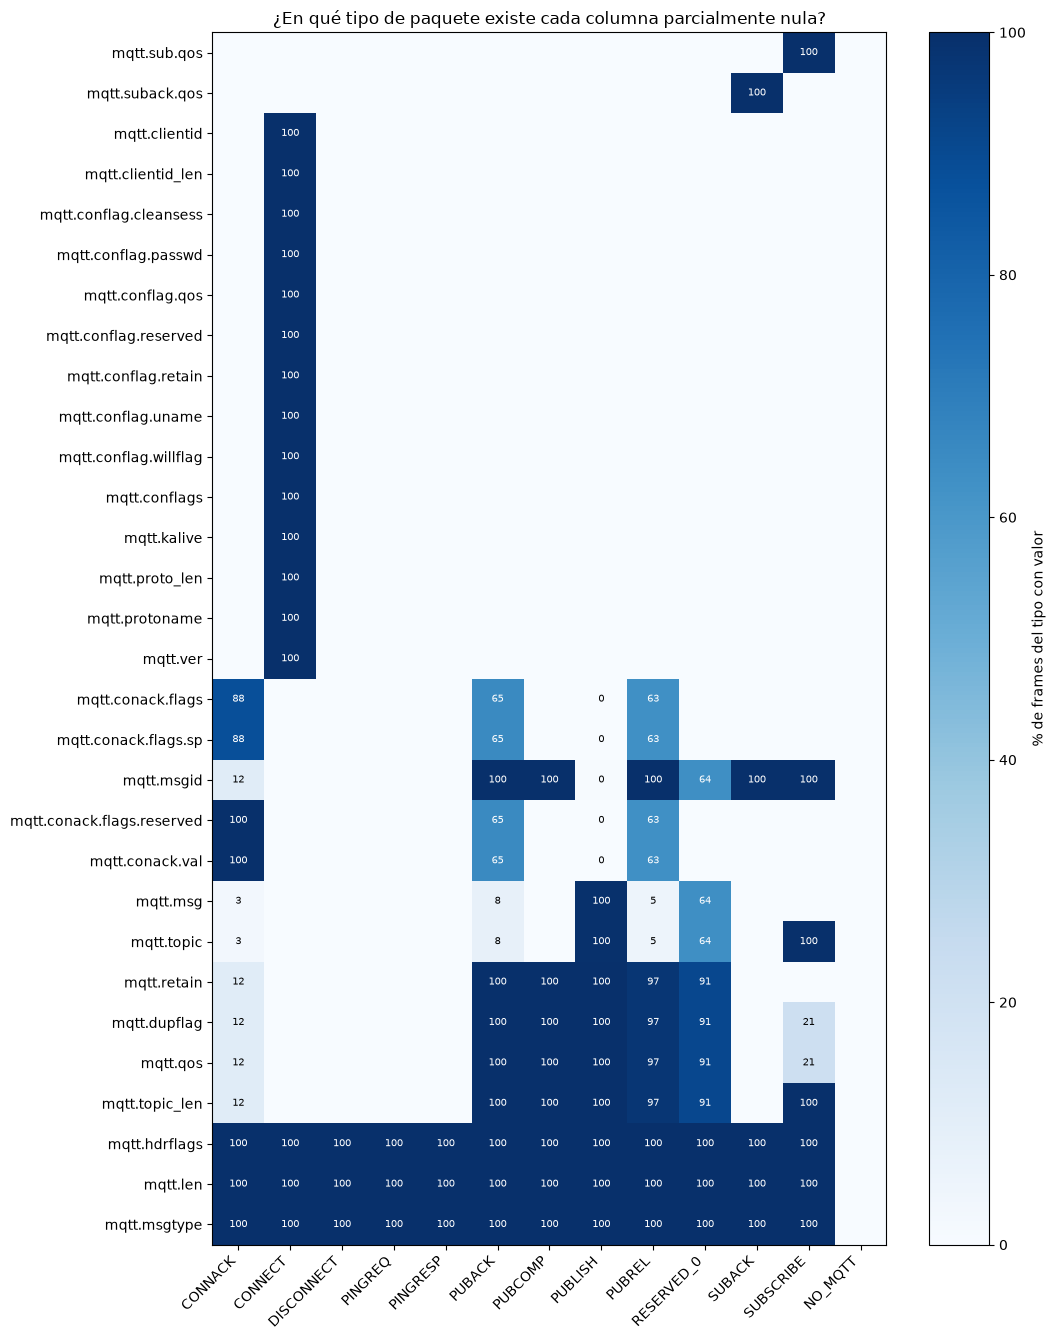

,count_normal,count_attack,pct_normal,pct_attack,ratio,separates
group,,,,,,
SUBSCRIBE,28,0,0.013208,0.000000,inf,True
SUBACK,29,0,0.013679,0.000000,inf,True
PUBCOMP,0,35,0.000000,0.076991,inf,True
PUBACK,0,162,0.000000,0.356357,inf,True
PUBREL,0,339,0.000000,0.745711,inf,True
RESERVED_0,0,22,0.000000,0.048394,inf,True
DISCONNECT,1,175,0.000472,0.384954,816.090519,True
PINGRESP,1922,5,0.906617,0.010999,82.429582,True
PINGREQ,1851,6,0.873126,0.013198,66.153813,True


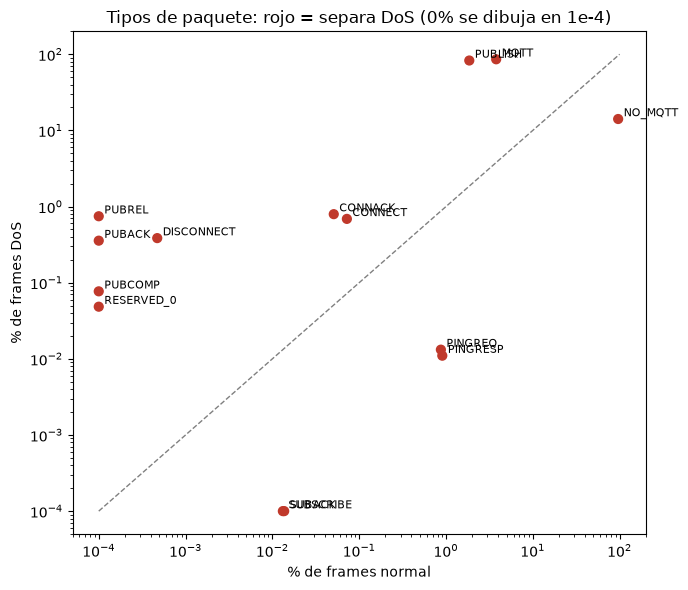

In [15]:
partial_columns = missingness.loc[
    missingness['non_null_count'].between(1, len(df_captured) - 1), 'column'].tolist()
alignment = eda.structural_null_alignment(df_captured, partial_columns)
display(alignment)
eda.plot_structural_presence(df_captured, partial_columns)

separation = eda.packet_type_separation(df_captured)
display(separation)
eda.plot_packet_separation(separation)

CONNECT separa por proporción de frames, así que sus columnas no constantes
(`mqtt.kalive`, `mqtt.clientid_len`, y con el normal de MitM/Intrusion también
`mqtt.ver`, `mqtt.proto_len` y `mqtt.protoname`) se marcan DERIVE: la señal útil
es cuántos CONNECT hay por ventana o por conexión, no el valor crudo. Las gráficas
lo muestran a nivel de conexión y la distribución de valores de esas columnas.

Los valores crudos describen el cliente, no el comportamiento: todo CONNECT DoS
usa MQTT 3.1.1 (`ver=4`, `MQTT`) y el 73% de los CONNECT normales usa MQTT 3.1
(`ver=3`, `MQIsdp`). Usarlos crudos enseñaría al modelo a reconocer la librería
de la herramienta de ataque.

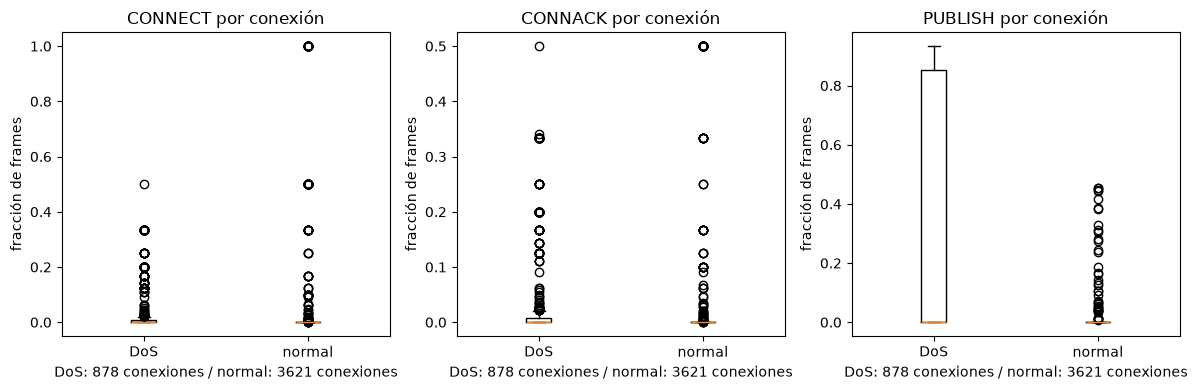

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
DoS,878.0,0.039459,0.090290,0.0,0.0,0.0,0.008132,0.5
normal,3621.0,0.018923,0.114379,0.0,0.0,0.0,0.000000,1.0


type,DoS,normal,pct_DoS,pct_normal
mqtt.kalive,,,,
15.0,5,41,1.6,26.8
60.0,308,112,98.4,73.2


type,DoS,normal,pct_DoS,pct_normal
mqtt.clientid_len,,,,
9.0,0,19,0.00,12.42
11.0,0,29,0.00,18.95
12.0,0,1,0.00,0.65
13.0,1,1,0.32,0.65
14.0,1,11,0.32,7.19
16.0,0,58,0.00,37.91
18.0,2,12,0.64,7.84
23.0,0,6,0.00,3.92
34.0,0,13,0.00,8.50


type,DoS,normal,pct_DoS,pct_normal
mqtt.ver,,,,
3.0,0,112,0.0,73.2
4.0,313,41,100.0,26.8


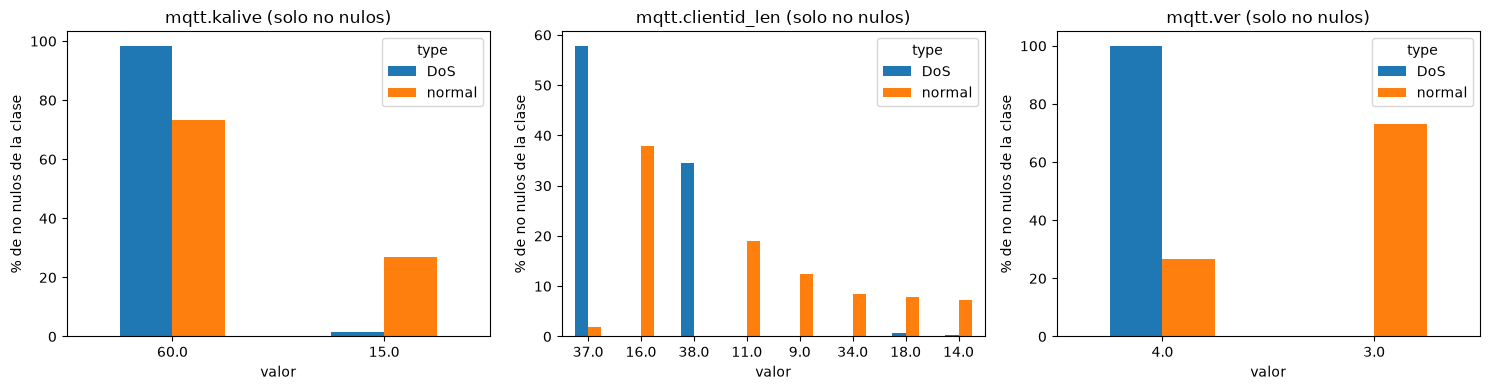

In [16]:
eda.plot_connection_packet_share(df_captured, ['CONNECT', 'CONNACK', 'PUBLISH'])
display(eda.connection_packet_share(df_captured, 'CONNECT')
        .groupby('label')['share'].describe())
for column in ['mqtt.kalive', 'mqtt.clientid_len', 'mqtt.ver']:
    display(eda.values_by_class(df_captured, column))
eda.plot_values_by_class(df_captured, ['mqtt.kalive', 'mqtt.clientid_len', 'mqtt.ver'])

### 2.6 Tabla de política

Una fila por columna capturada, sin celdas vacías. La justificación de las
decisiones dependientes de datos se genera con los números de 2.1–2.5.

Los DERIVE de CONNECT (nº de CONNECT por ventana/conexión) **no** se materializan
aquí: el modelo final usa solo features TCP (`tcp_features.py`, notebook 03), que ya
capturan la llegada de conexiones nuevas (`tcp_new_conns_5s`) sin leer campos MQTT.

,columna,semántica,motivo,acción,justificación frente a DoS
0,frame.time_delta,segundos desde el frame capturado anterior,BEHAVIOR,KEEP,ritmo entre frames; la inundación DoS lo acorta
1,frame.time_delta_displayed,segundos desde el frame mostrado anterior en tshark,DUPLICATE,DROP,idéntica a frame.time_delta en el 100% de filas; se conserva frame.time_delta
2,frame.time_epoch,instante absoluto de captura (Unix epoch),LEAKAGE,DROP,fecha de captura; solo se usa como contexto para ordenar ventanas
3,frame.time_invalid,marca de timestamp inválido,EMPTY,DROP,sin ningún valor observado
4,frame.time_relative,segundos desde el primer frame de la captura,LEAKAGE,DROP,momento dentro de la captura; separa por cuándo se grabó el ataque
5,ip.src,dirección IP de origen,LEAKAGE,DROP,"identifica al host, no el comportamiento"
6,ip.dst,dirección IP de destino,LEAKAGE,DROP,"identifica al host, no el comportamiento"
7,tcp.srcport,puerto TCP de origen,LEAKAGE,DERIVE,puerto efímero; solo se deriva fe_is_broker_to_client (origen 1883/8883)
8,tcp.dstport,puerto TCP de destino,LEAKAGE,DERIVE,puerto efímero; solo se deriva fe_is_standard_mqtt_port (destino 1883/8883)
9,eth.src,MAC de origen,LEAKAGE,DROP,"identifica la interfaz física, no el comportamiento"


columnas
acción motivo                   
DERIVE LEAKAGE                 2
       RAW_TEXT                2
       STRUCTURAL_NULL         5
DROP   CONSTANT               14
       DUPLICATE               2
       EMPTY                  19
       LEAKAGE                 8
       REDUNDANT               4
       STRUCTURAL_NULL         5
KEEP   BEHAVIOR                2
       STRUCTURAL_NULL         3

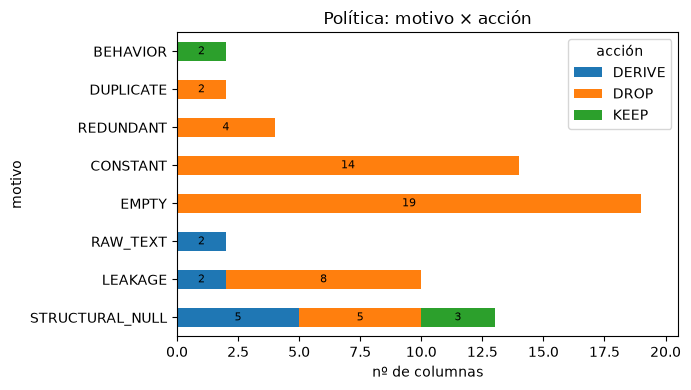

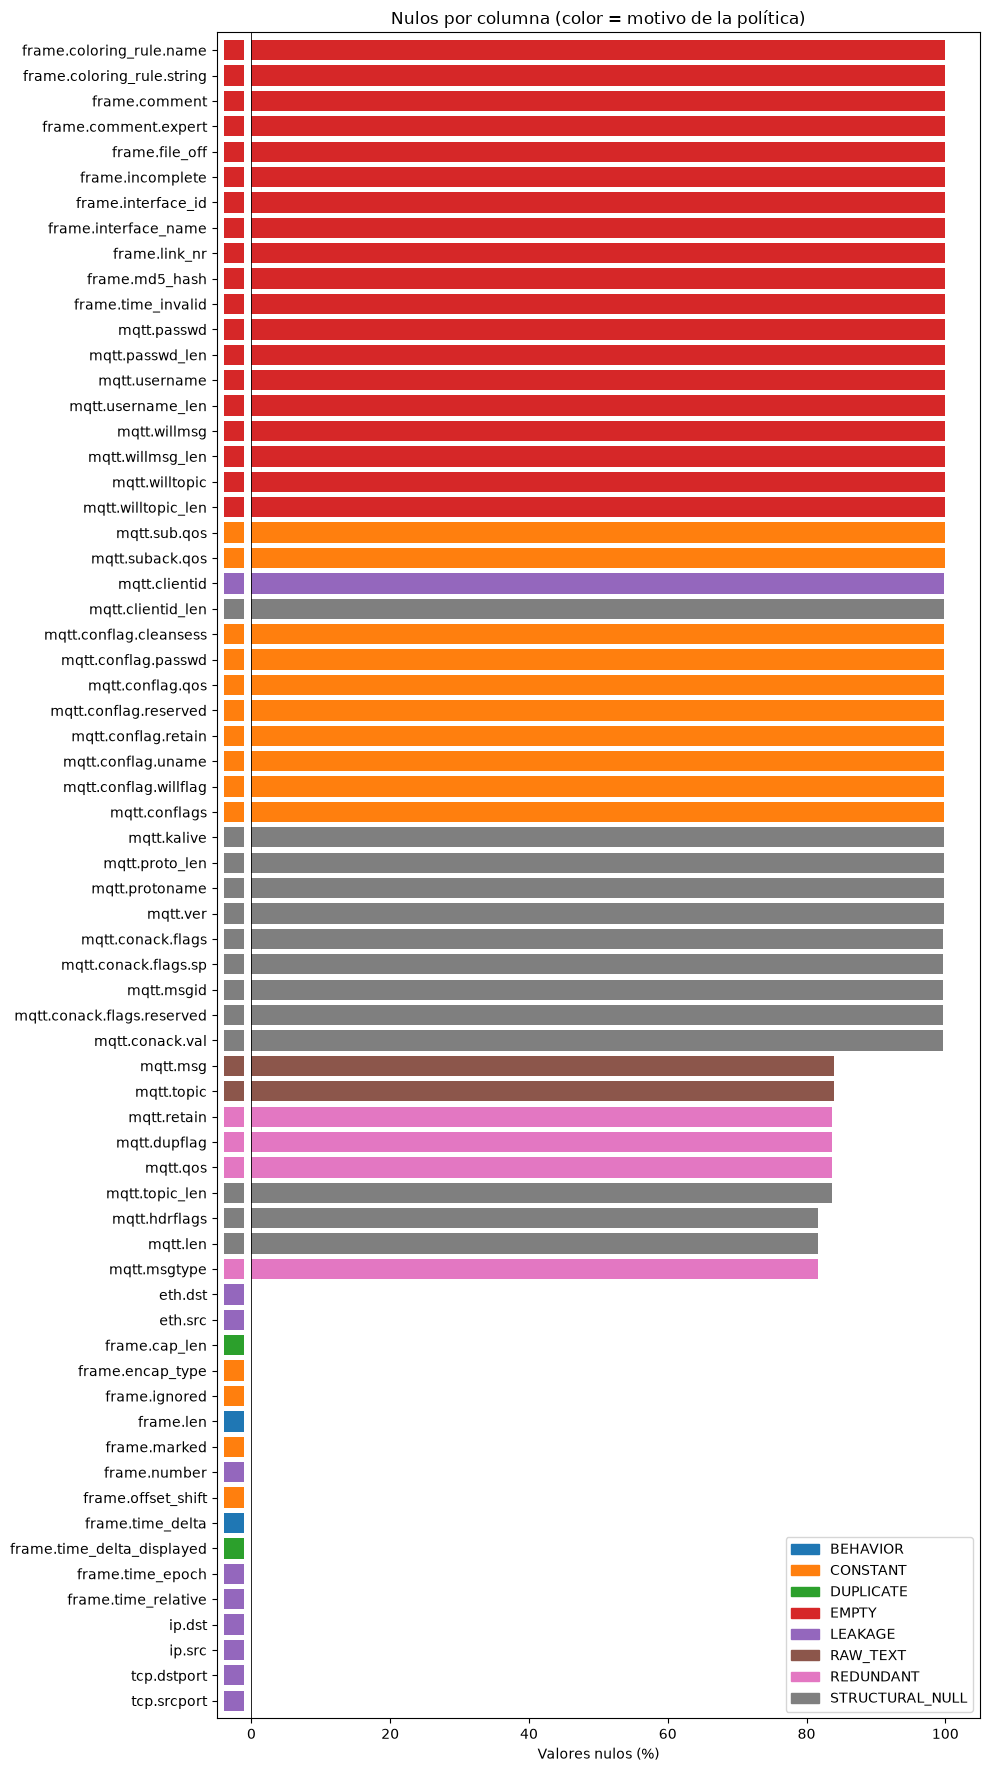

In [17]:
column_policy, policy_evidence = build_column_policy(df_captured)
display(column_policy)
display(column_policy.groupby(['acción', 'motivo']).size().rename('columnas').to_frame())
eda.plot_policy_summary(column_policy)
eda.plot_missingness(missingness, column_policy)

### 2.7 Aplicar la política

Se eliminan las columnas DROP, salvo `frame.time_epoch`: es `LEAKAGE` como
feature, pero se conserva como **contexto** para ordenar los frames de cada
ventana. Las columnas DERIVE siguen en el DataFrame porque la ingeniería de
features las lee; la matriz del modelo usa solo `FEATURE_COLUMNS`. Las claves
`_connection` y `_direction` ya se construyeron en la carga, así que IP, MAC y
`client_id` no hacen falta.

In [18]:
CONTEXT_COLUMNS = ['frame.time_epoch']
df_raw, dropped_columns = apply_column_policy(df_captured, column_policy, CONTEXT_COLUMNS)
print(f'Columnas eliminadas: {len(dropped_columns)}')
print('Columnas restantes:', sorted(c for c in df_raw.columns if not c.startswith('_')))

Columnas eliminadas: 51
Columnas restantes: ['frame.len', 'frame.time_delta', 'frame.time_epoch', 'mqtt.clientid_len', 'mqtt.hdrflags', 'mqtt.kalive', 'mqtt.len', 'mqtt.msg', 'mqtt.proto_len', 'mqtt.protoname', 'mqtt.topic', 'mqtt.topic_len', 'mqtt.ver', 'tcp.dstport', 'tcp.srcport', 'type']


### 2.8 Guardar el artefacto limpio

`df_raw` es la entrada de `02_tcp_vs_mqtt.ipynb` y `03_modelo_tcp.ipynb`; ninguno
de los dos vuelve a limpiar el dataset. Se guarda con `joblib` (no Parquet) porque
conserva los tuples de `_connection` y `_direction`.

La celda valida el contenido, guarda `df_raw.joblib`, lo recarga para comprobar que
las claves siguen siendo tuples y escribe `manifest.json` con capturas, conteos,
rol de cada columna, hashes, semilla y versión de features. Las columnas de contexto
(`frame.time_epoch`, `tcp.srcport`, `tcp.dstport`, claves `_*`) **no** son features
del modelo: los notebooks 02/03 solo las usan para agrupar, ordenar o derivar banderas.

In [19]:
from data_preprocessing.feature_engineering import FEATURE_COLUMNS as MQTT_FEATURE_COLUMNS
from data_preprocessing.tcp_features import TCP_FEATURE_COLUMNS

manifest = save_clean_artifact(df_raw, ARTIFACTS_DIR, dict(
    repo_root=REPO_ROOT, files=FILES, normal_only=NORMAL_ONLY,
    policy=column_policy, dropped_columns=dropped_columns, seed=SEED,
    feature_version='tcp-B-v1',
    feature_columns={'tcp_B': TCP_FEATURE_COLUMNS, 'mqtt_A': MQTT_FEATURE_COLUMNS},
    extra={'normal_concurrent_share_dos': round(float(NORMAL_CONCURRENT_SHARE), 4),
           'split_strategy': 'StratifiedGroupKFold por _connection' if not NEEDS_LOCO
                             else 'agrupado + leave-one-capture-out del normal'},
))

print(f"Artefacto: {manifest['artifact']}  shape={tuple(manifest['shape'].values())}")
print(f"sha256: {manifest['df_raw_sha256']}")
frames_by_class, connections_by_class = class_counts(df_raw)
display(frames_by_class.assign(total=frames_by_class.sum(axis=1)))
display(connections_by_class)
display(pd.Series(manifest['column_roles'], name='rol').rename_axis('columna').to_frame())

Artefacto: ML_Model/artifacts/df_raw.joblib  shape=(257457, 21)
sha256: 1554de54a5a32d6cc9047227712043c03ddd7bb8fee3b3b576ab48cd403921df


type,normal,DoS,total
_capture,,,
DoS,43000,45460,88460
Intrusion,69863,0,69863
MitM,99134,0,99134


type,normal,DoS
_capture,,
DoS,697,907
Intrusion,2067,0
MitM,864,0


,rol
columna,
frame.time_delta,keep
frame.time_epoch,context
tcp.srcport,context
tcp.dstport,context
frame.len,keep
mqtt.clientid_len,derive
mqtt.hdrflags,keep
mqtt.kalive,derive
mqtt.len,keep


## 3. Decisiones tomadas

**Etiquetas.** Binario `normal` / `DoS`. `DoS.csv` aporta sus dos clases;
`MitM.csv` e `Intrusion.csv` solo su tráfico `normal` (sus frames de ataque se
descartan, no se reetiquetan). Con la selección IPv4/TCP quedan 45.460 frames DoS
y 211.997 normales (43.000 de `DoS.csv`, 99.134 de MitM y 69.863 de Intrusion).

**Vistas.** Se mantienen dos vistas del mismo `df_raw`:
- `full`: todo el tráfico IPv4/TCP seleccionado.
- `mqtt`: solo frames con puerto 1883/8883 (`df_scope`), que se construye en los
  notebooks 02/03 a partir de `tcp.srcport`/`tcp.dstport`.

**Columnas de contexto.** `frame.time_epoch` (orden de ventanas), `tcp.srcport` /
`tcp.dstport` (banderas de puerto MQTT y filtro de la vista `mqtt`), `_connection`,
`_direction`, `_endpoints`, `_capture` y `_original_row` (agrupación, split y
trazabilidad). Ninguna es feature del modelo.

**Descartes.**
- *Identidad* (`ip.*`, `eth.*`, `mqtt.clientid`): identifica hosts o clientes; el
  modelo memorizaría quién, no qué hace. Las claves de sesión se construyen antes
  de descartarlas.
- *Puertos crudos*: el puerto de origen es efímero; como valor crudo el mismo
  ataque cambia de etiqueta según el puerto (leakage). Solo se derivan banderas.
- *Reloj* (`frame.time_relative`, `frame.number`, `frame.time_epoch` como feature):
  separan por cuándo se grabó el ataque, no por su comportamiento.
- *Valores crudos de CONNECT* (`mqtt.ver`, `mqtt.protoname`…): describen la
  librería del cliente (todo CONNECT DoS es MQTT 3.1.1), no el ataque.

**Split.** El 58,6 % (568/969) del normal MQTT de `DoS.csv` ocurre dentro de la
ventana del ataque, por encima del umbral del 20 %: se mantiene
`StratifiedGroupKFold` agrupado por `_connection` y no se exige
leave-one-capture-out.

**Sesgo de distribución → features TCP.** El normal es mayoritariamente no-MQTT y
el DoS casi todo MQTT (2.3, 2.3.1): reglas triviales como "puerto MQTT ⇒ DoS" ya
separan las clases. Un modelo con campos `mqtt.*` aprendería "es MQTT" en lugar de
"es DoS", y esos campos no son observables con MQTTS. Por eso el modelo final usa
solo features TCP (opción B, `tcp_features.py`); la comparación está en
`02_tcp_vs_mqtt.ipynb`. **No** se borra el normal no-MQTT para corregir el sesgo:
eso crearía un dataset artificial.

**Limitación.** Solo hay una captura DoS (`DoS.csv`, un único escenario de
flood). Las métricas que se obtengan valen para ese escenario, no para cualquier
DoS; falta validarlas en caliente con el simulador (conexiones persistentes,
otras tasas y TLS en 8883).